<a href="https://colab.research.google.com/github/RasyaArdhiansyach/DM-2026-A11.2024.15900/blob/main/Breast%20Cancer%20Wisconsin/Breast_Cancer_Wisconsin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Breast Cancer Wisconsin
Dataset Source : https://archive.ics.uci.edu/dataset/15/breast+cancer+wisconsin+original

MUHAMMAD RASYA ARDHIAN SYACH // A11.2024.15900

Import Library dan Load Dataset

In [9]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Nama kolom sesuai struktur dataset
columns = [
    'Sample_code_number', 'Clump_thickness', 'Uniformity_of_cell_size',
    'Uniformity_of_cell_shape', 'Marginal_adhesion', 'Single_epithelial_cell_size',
    'Bare_nuclei', 'Bland_chromatin', 'Normal_nucleoli', 'Mitoses', 'Class'
]

# Load dataset
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv('/content/drive/My Drive/Data Mining 2026/dataset/breast-cancer-wisconsin.data', names=columns)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Handle Missing Values (Data Cleaning)

In [10]:
# Hapus kolom ID karena cuma berperan sebagai ID categorical
df.drop('Sample_code_number', axis=1, inplace=True)

# Mengganti missing values '?' dengan representasi missing value (NaN)
df.replace('?', np.nan, inplace=True)

# Ubah tipe data Bare_nuclei jadi numerik dan isi nilai NaN dengan median
df['Bare_nuclei'] = pd.to_numeric(df['Bare_nuclei'])
df['Bare_nuclei'] = df['Bare_nuclei'].fillna(df['Bare_nuclei'].median())

Exploratory Data Analysis

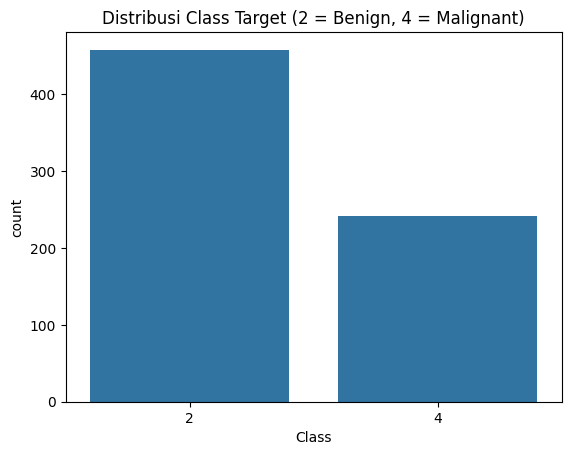

In [11]:
# Tampilkan perbandingan jumlah diagnosis jinak dan ganas
sns.countplot(data=df, x='Class')
plt.title('Distribusi Class Target (2 = Benign, 4 = Malignant)')
plt.show()

Classification Task

In [12]:
# Pisahkan fitur dan target
X = df.drop('Class', axis=1)
y = df['Class']

# Bagi data training dan data testing (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Training model klasifikasi (Random Forest)
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# Memprediksi data uji
y_pred = model.predict(X_test)

Evaluasi Model (Skor akurasi model dalam membedakan tumor jinak dan ganas pada data uji)



In [13]:
print("Akurasi Model:", accuracy_score(y_test, y_pred))
print("\nLaporan Klasifikasi:\n", classification_report(y_test, y_pred))

Akurasi Model: 0.9642857142857143

Laporan Klasifikasi:
               precision    recall  f1-score   support

           2       0.97      0.98      0.97        95
           4       0.95      0.93      0.94        45

    accuracy                           0.96       140
   macro avg       0.96      0.96      0.96       140
weighted avg       0.96      0.96      0.96       140

